# 03 · LightGCN, TAS-GNN và bảng so sánh chung

- **TAS-GNN** là mô hình chính của đồ án: xương sống LightGCN 3 lớp, thêm bộ mã hóa thời gian (Fourier + embedding giờ/thứ), cổng thời gian cho người dùng, bộ mã hóa không gian và embedding loại địa điểm.
- **LightGCN** là mô hình đối chứng: cùng đồ thị, không có thời gian và không gian.

Hai mô hình **không huấn luyện lại** ở đây: notebook nạp checkpoint có sẵn trong `outputs/checkpoints/` (huấn luyện trên 70% đầu; đồ thị lan truyền dựng từ 80% đầu, 20% test không lọt vào đồ thị).

Cần chạy notebook 01 và 02 trước để có kết quả của 7 baseline.

In [1]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Tìm thư mục gốc dự án (nơi có src/benchmark_ml.py) dù notebook được mở từ đâu.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "benchmark_ml.py").is_file())
sys.path[:0] = [str(ROOT), str(ROOT / "src")]
import benchmark_ml as bm

warnings.filterwarnings("ignore")
INK, SEA, CORAL, SAND, SKY, MUTED = "#1d2b2f", "#1f6f78", "#c8553d", "#b8860b", "#3d6a9e", "#9aa5a8"
GROUP_COLOR = {"heuristic": SAND, "ml": SKY, "gnn": SEA}
GROUP_NAME = {"heuristic": "Heuristic", "ml": "Machine learning cổ điển", "gnn": "Mạng nơ-ron đồ thị"}
CATEGORY_NAME = {"cafe": "Cà phê", "restaurant": "Ăn uống", "hotel": "Lưu trú", "tourist_spot": "Tham quan"}
CATEGORY_COLOR = {"cafe": SAND, "restaurant": CORAL, "hotel": SKY, "tourist_spot": SEA}
LABEL = {key: label for key, label, _ in bm.MODELS}
GROUP = {key: group for key, _, group in bm.MODELS}
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (9, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.edgecolor": MUTED, "text.color": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK})

bench = bm.prepare()
print(f"{bench.n_users:,} người dùng · {bench.n_items:,} địa điểm · {len(bench.events):,} lượt check-in")
print(f"Train {len(bench.train):,} · Test {len(bench.test):,} · Test tại địa điểm mới (được chấm) {len(bench.novel):,}")


def color_of(key):
    return CORAL if key == "tas_gnn" else GROUP_COLOR[GROUP[key]]


def show_results(ranks, title, metric="HR@10"):
    """Bảng chỉ số (%) và biểu đồ cột của các phương pháp đã có kết quả."""
    table = bm.results_table(ranks)
    display(table.drop(columns=["model", "group"]).rename(columns={"label": "Phương pháp"}).set_index("Phương pháp")
            .style.format("{:.2f}").background_gradient(cmap="YlGn", axis=0))
    ordered = table.sort_values(metric)
    fig, ax = plt.subplots(figsize=(9, .5 * len(ordered) + 1.4))
    bars = ax.barh(ordered.label, ordered[metric], color=[color_of(k) for k in ordered.model])
    ax.bar_label(bars, fmt="%.2f%%", padding=4)
    ax.set(xlabel=f"{metric} (%)", title=title, xlim=(0, ordered[metric].max() * 1.18))
    ax.grid(axis="y", visible=False)
    plt.show()
    return table


1,500 người dùng · 996 địa điểm · 36,210 lượt check-in
Train 28,360 · Test 7,850 · Test tại địa điểm mới (được chấm) 6,811


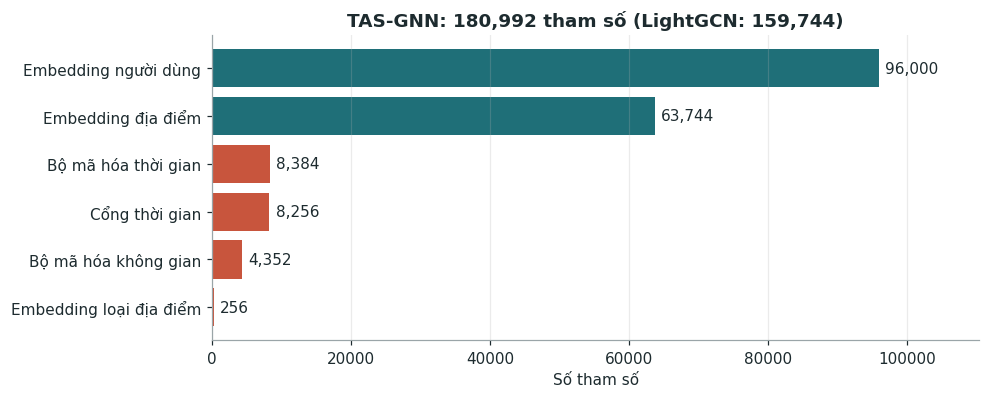

Phần thời gian, không gian và loại địa điểm chỉ thêm 21,248 tham số (13.3% so với LightGCN).


In [2]:
import torch
from ml.repo_models import load_repo_models

repo = load_repo_models(ROOT)
info = repo.info
BLOCK_NAME = {"userEmbedding": "Embedding người dùng", "poiEmbedding": "Embedding địa điểm", "timeEncoder": "Bộ mã hóa thời gian",
              "temporalGate": "Cổng thời gian", "spatialEncoder": "Bộ mã hóa không gian", "categoryEmbedding": "Embedding loại địa điểm"}
blocks = pd.Series(info["blocks"]).rename(BLOCK_NAME).sort_values()
fig, ax = plt.subplots(figsize=(9, 3.6))
bars = ax.barh(blocks.index, blocks.values, color=[SEA if "Embedding người" in n or "Embedding địa" in n else CORAL for n in blocks.index])
ax.bar_label(bars, labels=[f"{v:,}" for v in blocks.values], padding=4)
ax.set(title=f"TAS-GNN: {info['parameters']:,} tham số (LightGCN: {info['lightgcnParameters']:,})", xlabel="Số tham số", xlim=(0, blocks.max() * 1.15))
ax.grid(axis="y", visible=False)
plt.show()
extra = info["parameters"] - info["lightgcnParameters"]
print(f"Phần thời gian, không gian và loại địa điểm chỉ thêm {extra:,} tham số ({extra / info['lightgcnParameters']:.1%} so với LightGCN).")

## 1. Chấm LightGCN và TAS-GNN

Thêm một dòng kiểm tra: **cùng checkpoint TAS-GNN nhưng tắt nhánh thời gian lúc suy luận**. Đây không phải ablation huấn luyện lại (bản đó nằm ở `src/ablation_study.py`); nó chỉ cho thấy mô hình đã huấn luyện dựa vào tín hiệu thời gian nhiều đến đâu.

LightGCN   chấm 6,811 sự kiện trong 0.1 s


TAS-GNN    chấm 6,811 sự kiện trong 0.1 s


,HR@5,NDCG@5,MRR@5,HR@10,NDCG@10,MRR@10,HR@20,NDCG@20,MRR@20
LightGCN,6.81,4.37,3.57,11.13,5.76,4.15,16.15,7.03,4.49
TAS-GNN · tắt thời gian,2.19,1.37,1.10,3.96,1.93,1.33,7.21,2.75,1.55
TAS-GNN · đầy đủ,7.39,4.46,3.52,12.45,6.09,4.18,18.56,7.62,4.59


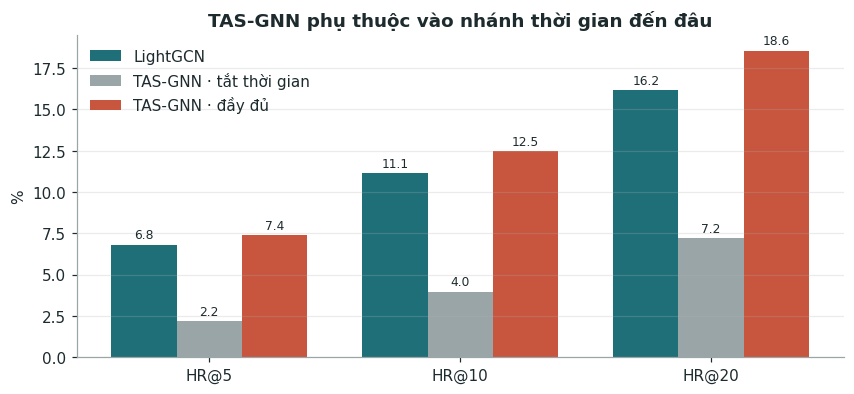

In [3]:
scorers = bm.gnn_scorers(repo)
ranks_gnn = {}
for key in ("lightgcn", "tas_gnn"):
    start = time.perf_counter()
    ranks_gnn[key] = bm.evaluate(bench, scorers[key])
    bm.save_ranks(key, ranks_gnn[key], 0.0, "checkpoint trong repo, không huấn luyện lại")
    print(f"{LABEL[key]:<10} chấm {len(ranks_gnn[key]):,} sự kiện trong {time.perf_counter() - start:.1f} s")
no_time = bm.evaluate(bench, lambda chunk: scorers["tas_gnn"](chunk, use_time=False))

ablation = pd.DataFrame({"LightGCN": bm.rank_metrics(ranks_gnn["lightgcn"]), "TAS-GNN · tắt thời gian": bm.rank_metrics(no_time),
                         "TAS-GNN · đầy đủ": bm.rank_metrics(ranks_gnn["tas_gnn"])}).T * 100
display(ablation.style.format("{:.2f}").background_gradient(cmap="YlGn", axis=0))
fig, ax = plt.subplots(figsize=(9, 3.8))
x, width = np.arange(3), .26
for i, (name, color) in enumerate(zip(ablation.index, (SEA, MUTED, CORAL))):
    bars = ax.bar(x + (i - 1) * width, ablation.loc[name, ["HR@5", "HR@10", "HR@20"]], width, label=name, color=color)
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
ax.set(title="TAS-GNN phụ thuộc vào nhánh thời gian đến đâu", xticks=x, xticklabels=["HR@5", "HR@10", "HR@20"], ylabel="%")
ax.grid(axis="x", visible=False); ax.legend(frameon=False)
plt.show()

## 2. Cơ chế thời gian nhìn bằng mắt

Cùng một người dùng, cùng một ngày, chỉ đổi **giờ**: top 10 của TAS-GNN thay đổi thế nào? LightGCN không có đầu vào thời gian nên danh sách của nó đứng yên.

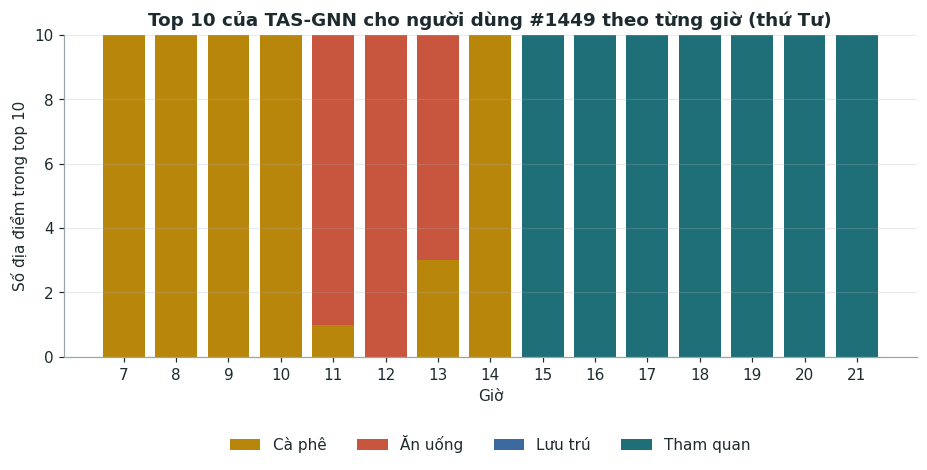

Lịch sử của người dùng #1449: Cà phê 35, Tham quan 4, Ăn uống 1


,8 giờ,12 giờ,20 giờ
#1,QuynhMai Coffee (Cà phê),Good Banh My (Ăn uống),Lang Bich hoa Da Nang (Tham quan)
#2,NgocAnh Coffee (Cà phê),The Pizza Company (Ăn uống),Dragon's Head (Tham quan)
#3,CaPhe Rang Dong (Cà phê),Quan Mau Banh Trang Thit (Ăn uống),Cầu Tiên Sơn (Tham quan)
#4,NgocVan Coffee (Cà phê),Quán Chay Hang Ngay (Ăn uống),Dragon's Tail (Tham quan)
#5,TinaCoffee (Cà phê),Quan Com Ga A.HAI (Ăn uống),Dragon Bridge East Viewp (Tham quan)


In [4]:
user = int(bench.train.merge(bench.pois[["l", "category"]], on="l").query("category == 'cafe'").u.value_counts().index[0])
timestamp = float(bench.train.ts.median())
hours = list(range(7, 22))
categories = list(CATEGORY_NAME)
mix = np.zeros((len(categories), len(hours)))
tops = {}
for column, hour in enumerate(hours):
    scores = repo.score("tas_gnn", user, hour, 2, timestamp)
    scores[bench.seen[user]] = -np.inf
    top = np.argsort(-scores)[:10]
    tops[hour] = top
    for row, category in enumerate(categories):
        mix[row, column] = (bench.pois.category[top] == category).sum()

fig, ax = plt.subplots(figsize=(10, 3.8))
bottom = np.zeros(len(hours))
for row, category in enumerate(categories):
    ax.bar(hours, mix[row], bottom=bottom, color=CATEGORY_COLOR[category], label=CATEGORY_NAME[category])
    bottom += mix[row]
ax.set(title=f"Top 10 của TAS-GNN cho người dùng #{user} theo từng giờ (thứ Tư)", xlabel="Giờ", ylabel="Số địa điểm trong top 10", xticks=hours)
ax.grid(axis="x", visible=False); ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(.5, -.2))
plt.show()
history = bench.pois.category[bench.train[bench.train.u == user].l].map(CATEGORY_NAME).value_counts()
print(f"Lịch sử của người dùng #{user}:", ", ".join(f"{name} {count}" for name, count in history.items()))
display(pd.DataFrame({f"{hour} giờ": [f"{bench.pois.name[i][:24]} ({CATEGORY_NAME[bench.pois.category[i]]})" for i in tops[hour][:5]] for hour in (8, 12, 20)},
                     index=[f"#{i}" for i in range(1, 6)]))

## 3. Bảng so sánh chung 9 phương pháp

,HR@5,NDCG@5,MRR@5,HR@10,NDCG@10,MRR@10,HR@20,NDCG@20,MRR@20
Phương pháp,,,,,,,,,
Phổ biến chung,2.17,1.01,0.65,6.12,2.29,1.17,11.19,3.56,1.51
Phổ biến theo giờ,6.33,3.78,2.95,10.53,5.13,3.50,16.37,6.61,3.91
Giờ × khoảng cách liền trước,9.90,6.54,5.44,14.64,8.05,6.05,21.79,9.85,6.54
User-KNN,6.33,4.09,3.36,10.35,5.38,3.89,15.49,6.67,4.24
Item-KNN,5.77,3.93,3.33,9.10,5.00,3.76,13.82,6.17,4.08
BPR-MF,4.07,2.63,2.16,6.24,3.32,2.44,9.93,4.24,2.69
Gradient Boosting (đặc trưng),7.71,4.90,3.98,13.93,6.90,4.80,20.44,8.54,5.26
LightGCN,6.81,4.37,3.57,11.13,5.76,4.15,16.15,7.03,4.49
TAS-GNN,7.39,4.46,3.52,12.45,6.09,4.18,18.56,7.62,4.59


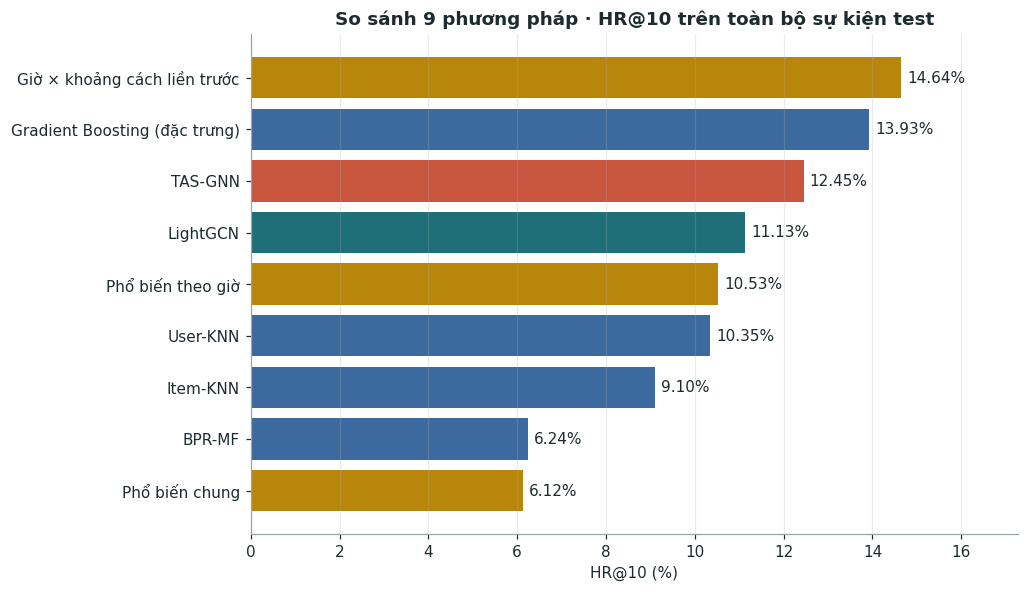

Màu: vàng = heuristic · xanh dương = machine learning cổ điển · xanh lục = LightGCN · cam đỏ = TAS-GNN (mô hình chính)


In [5]:
ranks, seconds, notes = bm.load_ranks()
missing = [LABEL[key] for key, _, _ in bm.MODELS if key not in ranks]
assert not missing, f"Chưa có kết quả của: {', '.join(missing)}. Hãy chạy notebook 01 và 02 trước."
table = show_results(ranks, "So sánh 9 phương pháp · HR@10 trên toàn bộ sự kiện test")
print("Màu: vàng = heuristic · xanh dương = machine learning cổ điển · xanh lục = LightGCN · cam đỏ = TAS-GNN (mô hình chính)")

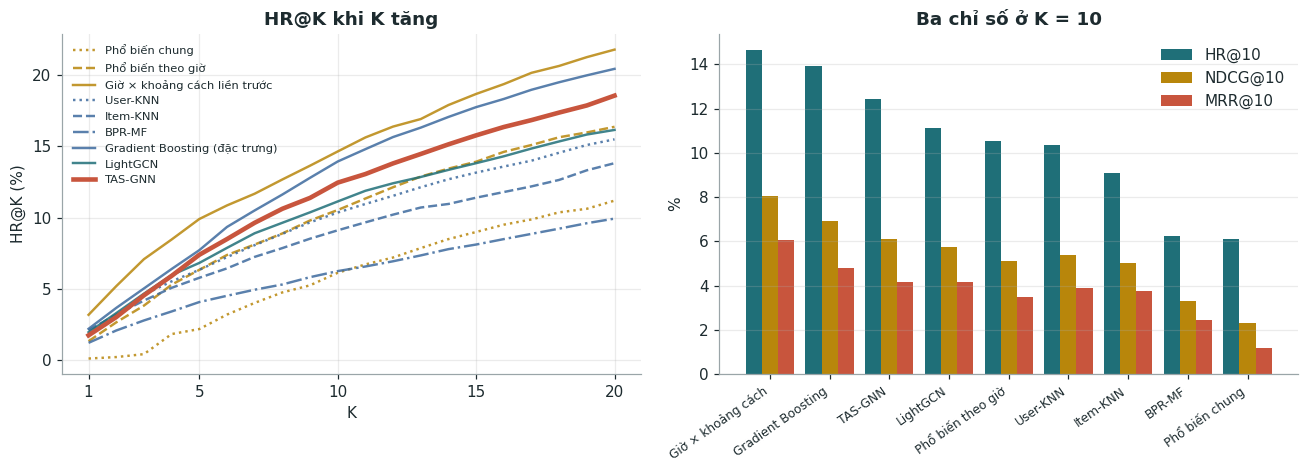

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ks = np.arange(1, 21)
for key, label, group in bm.MODELS:
    main = key == "tas_gnn"
    axes[0].plot(ks, [(ranks[key] <= k).mean() * 100 for k in ks], lw=3 if main else 1.6, color=color_of(key),
                 ls={"popularity": ":", "hourly_popularity": "--", "user_knn": ":", "item_knn": "--", "bpr_mf": "-."}.get(key, "-"),
                 alpha=1 if main else .85, label=label)
axes[0].set(title="HR@K khi K tăng", xlabel="K", ylabel="HR@K (%)", xticks=[1, 5, 10, 15, 20])
axes[0].legend(fontsize=7.5, frameon=False)

ordered = table.sort_values("HR@10", ascending=False)
x, width = np.arange(len(ordered)), .27
for i, (metric, color) in enumerate(zip(("HR@10", "NDCG@10", "MRR@10"), (SEA, SAND, CORAL))):
    axes[1].bar(x + (i - 1) * width, ordered[metric], width, label=metric, color=color)
axes[1].set(title="Ba chỉ số ở K = 10", xticks=x, ylabel="%")
axes[1].set_xticklabels([l.replace(" (đặc trưng)", "").replace("Giờ × khoảng cách liền trước", "Giờ × khoảng cách") for l in ordered.label], rotation=35, ha="right", fontsize=8)
axes[1].grid(axis="x", visible=False); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

## 4. Mô hình nào mạnh ở đâu

Tách kết quả theo **khung giờ** của sự kiện và theo **loại địa điểm** đúng, để thấy điểm mạnh và điểm yếu chứ không chỉ một con số trung bình.

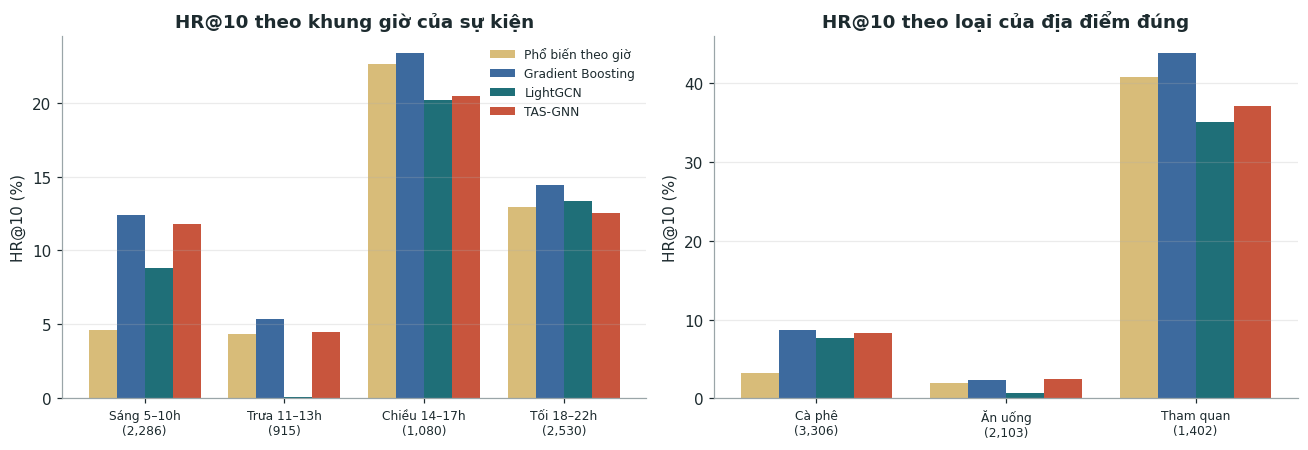

In [7]:
novel = bench.novel.merge(bench.pois[["l", "category"]], on="l", how="left")
slots = pd.cut(novel.hour, [-1, 4, 10, 13, 17, 22, 24], labels=["Đêm khuya", "Sáng 5–10h", "Trưa 11–13h", "Chiều 14–17h", "Tối 18–22h", "Đêm khuya "])
slots = slots.astype(str).str.strip()
slot_order = [s for s in ["Sáng 5–10h", "Trưa 11–13h", "Chiều 14–17h", "Tối 18–22h", "Đêm khuya"] if (slots == s).sum() >= 50]
focus = ["hourly_popularity", "feature_gbm", "lightgcn", "tas_gnn"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
x, width = np.arange(len(slot_order)), .2
for i, key in enumerate(focus):
    values = [(ranks[key][(slots == s).to_numpy()] <= 10).mean() * 100 for s in slot_order]
    axes[0].bar(x + (i - 1.5) * width, values, width, label=LABEL[key].replace(" (đặc trưng)", ""), color=color_of(key), alpha=.55 if key == "hourly_popularity" else 1)
axes[0].set(title="HR@10 theo khung giờ của sự kiện", xticks=x, ylabel="HR@10 (%)")
axes[0].set_xticklabels([f"{s}\n({(slots == s).sum():,})" for s in slot_order], fontsize=8)
axes[0].grid(axis="x", visible=False); axes[0].legend(frameon=False, fontsize=8)

present = [c for c in CATEGORY_NAME if (novel.category == c).sum() >= 50]
x = np.arange(len(present))
for i, key in enumerate(focus):
    values = [(ranks[key][(novel.category == c).to_numpy()] <= 10).mean() * 100 for c in present]
    axes[1].bar(x + (i - 1.5) * width, values, width, color=color_of(key), alpha=.55 if key == "hourly_popularity" else 1)
axes[1].set(title="HR@10 theo loại của địa điểm đúng", xticks=x, ylabel="HR@10 (%)")
axes[1].set_xticklabels([f"{CATEGORY_NAME[c]}\n({(novel.category == c).sum():,})" for c in present], fontsize=8)
axes[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

In [8]:
hit = {key: ranks[key] <= 10 for key in ranks}
tas, gbm_hit, light = hit["tas_gnn"], hit["feature_gbm"], hit["lightgcn"]
print(f"Trong {len(tas):,} sự kiện test:")
print(f"  TAS-GNN trúng top 10: {tas.sum():,} · Gradient Boosting: {gbm_hit.sum():,} · LightGCN: {light.sum():,}")
print(f"  TAS-GNN trúng mà Gradient Boosting trượt: {(tas & ~gbm_hit).sum():,} · ngược lại: {(gbm_hit & ~tas).sum():,} · cả hai cùng trúng: {(tas & gbm_hit).sum():,}")
print(f"  TAS-GNN trúng mà LightGCN trượt: {(tas & ~light).sum():,} · ngược lại: {(light & ~tas).sum():,}")
either = (tas | gbm_hit).mean()
print(f"  Nếu ghép được hai mô hình một cách lý tưởng, HR@10 tối đa là {either:.2%}.")

Trong 6,811 sự kiện test:
  TAS-GNN trúng top 10: 848 · Gradient Boosting: 949 · LightGCN: 758
  TAS-GNN trúng mà Gradient Boosting trượt: 191 · ngược lại: 292 · cả hai cùng trúng: 657
  TAS-GNN trúng mà LightGCN trượt: 269 · ngược lại: 179
  Nếu ghép được hai mô hình một cách lý tưởng, HR@10 tối đa là 16.74%.


## 5. Ghi kết quả cho website

Ghi `outputs/benchmark_ml_danang.csv` và `FE/public/artifacts/benchmark-ml.json` (trang `/evaluation` đọc file này).

In [9]:
report = bm.write_report(bench, ranks, seconds, notes)
hr = {row["key"]: row["metrics"]["HR@10"] for row in report["models"]}
ranking = sorted(hr, key=hr.get, reverse=True)
print("Đã ghi outputs/benchmark_ml_danang.csv và FE/public/artifacts/benchmark-ml.json\n")
print("Xếp hạng theo HR@10:")
for place, key in enumerate(ranking, 1):
    print(f"  {place}. {LABEL[key]:<32} {hr[key]:.2%}{'   ← mô hình chính' if key == 'tas_gnn' else ''}")
print(f"\nTAS-GNN so với LightGCN: {hr['tas_gnn'] / hr['lightgcn'] - 1:+.1%} tương đối.")
print(f"TAS-GNN so với Gradient Boosting: {hr['tas_gnn'] / hr['feature_gbm'] - 1:+.1%} tương đối.")

Đã ghi outputs/benchmark_ml_danang.csv và FE/public/artifacts/benchmark-ml.json

Xếp hạng theo HR@10:
  1. Giờ × khoảng cách liền trước     14.64%
  2. Gradient Boosting (đặc trưng)    13.93%
  3. TAS-GNN                          12.45%   ← mô hình chính
  4. LightGCN                         11.13%
  5. Phổ biến theo giờ                10.53%
  6. User-KNN                         10.35%
  7. Item-KNN                         9.10%
  8. BPR-MF                           6.24%
  9. Phổ biến chung                   6.12%

TAS-GNN so với LightGCN: +11.9% tương đối.
TAS-GNN so với Gradient Boosting: -10.6% tương đối.


## Kết luận

Đọc cùng các con số in ở ô trên:

- **TAS-GNN hơn LightGCN** ở HR@5, HR@10 và HR@20. Mô hình thật sự dùng tín hiệu thời gian: tắt nhánh thời gian lúc suy luận thì HR@10 rơi xuống thấp hơn cả LightGCN (mục 1), và danh sách gợi ý đổi theo giờ đúng với quy luật của dữ liệu (mục 2).
- LightGCN gần như không trúng sự kiện buổi trưa và địa điểm ăn uống (mục 4); TAS-GNN lấy lại được phần này nhờ biết giờ.
- **TAS-GNN hơn cả ba phương pháp lọc cộng tác** (User-KNN, Item-KNN, BPR-MF) và baseline phổ biến theo giờ.
- **TAS-GNN chưa hơn Gradient Boosting và heuristic giờ × khoảng cách.** Hai phương pháp này được cấp trực tiếp tín hiệu khoảng cách (tâm hoạt động của người dùng, hoặc vị trí ngay trước đó), còn TAS-GNN chỉ nhận tọa độ địa điểm qua một bộ mã hóa không gian nhỏ. Đây là hạn chế cần nêu rõ khi bảo vệ, và là hướng cải tiến trực tiếp: đưa khoảng cách tới vị trí hiện tại vào mô hình.
- Trên website, TAS-GNN chỉ làm bước **tạo ứng viên**; khoảng cách, giá và đánh giá được bổ sung ở bước xếp hạng lại AHP-TOPSIS, nên điểm yếu về khoảng cách được bù ở tầng sau.

Dữ liệu check-in là dữ liệu **mô phỏng** trên các địa điểm thật từ OpenStreetMap, nên các con số nói về khả năng học lại quy luật của bộ mô phỏng, chưa phải hành vi du khách thật.